# Minería de Datos · Proyecto AUTOGEST
## Análisis de Datos de Siniestralidad Vial, Flujo de Tráfico y Gestión de Taller
**Ingeniería de Sistemas · Metodología CRISP-DM**

Este cuaderno realiza la carga, diagnóstico, limpieza, exportación individual e integración de los datasets de:
1. **Accidentes de Tránsito** (Siniestralidad Vial en Colombia)
2. **Taller y Mantenimiento** (Gestión de Flota, Grúas y Costos Mecánicos)
3. **Tráfico Vehicular** (Estaciones de Peaje e Infraestructura Carretera)


## 1. Importación de librerías y clases modulares


In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")

from src.accidentes import Accidentes
from src.taller import Taller
from src.trafico import Trafico
from src.integracion import Integracion


## 2. Dataset de Accidentes de Tránsito
### 2.1 Carga de los datos


In [2]:
acc = Accidentes("../dataset/accidentes.csv")
df_acc = acc.cargar()
print("Muestra inicial de registros de accidentes:")
display(df_acc.head())


NameError: name 'Accidentes' is not defined

### 2.2 Diagnóstico inicial de calidad


In [ ]:
acc.diagnosticar()


DIAGNÓSTICO INICIAL · ACCIDENTES DE TRÁNSITO
Filas: 633,298
Columnas: 6

Valores nulos por columna:
FECHA HECHO     0
COD_DEPTO       0
DEPARTAMENTO    0
COD_MUNI        0
MUNICIPIO       0
CANTIDAD        0
dtype: int64

Duplicados exactos: 287,996



### 2.3 Limpieza de datos (normalización, deduplicación y códigos DANE)


In [ ]:
df_acc_limpio = acc.limpiar()
print("Muestra limpia:")
display(df_acc_limpio.head())


Muestra limpia:



,FECHA HECHO,COD_DEPTO,DEPARTAMENTO,COD_MUNI,MUNICIPIO,CANTIDAD,CODIGO_DANE_MUNICIPIO,FECHA,AÑO,MES
0,31/07/2026,05,ANTIOQUIA,5147,CAREPA,1,05147,2026-07-31,2026,7
1,31/07/2026,76,VALLE DEL CAUCA,76147,CARTAGO,1,76147,2026-07-31,2026,7
2,31/07/2026,76,VALLE DEL CAUCA,76248,EL CERRITO,1,76248,2026-07-31,2026,7
3,31/07/2026,18,CAQUETA,18001,FLORENCIA,1,18001,2026-07-31,2026,7
4,31/07/2026,50,META,50287,FUENTE DE ORO,1,50287,2026-07-31,2026,7


### 2.4 Exportación del dataset limpio


In [ ]:
acc.guardar("../dataset/accidentes_limpio.csv")


[OK] Archivo de accidentes limpio guardado correctamente en: ..\dataset\accidentes_limpio.csv
Dimensiones finales: 345,302 filas × 10 columnas



## 3. Dataset de Taller y Mantenimiento de Flota
### 3.1 Carga de los datos


In [ ]:
tal = Taller("../dataset/taller.csv")
df_tal = tal.cargar()
print("Muestra inicial de registros de taller:")
display(df_tal.head())


Muestra inicial de registros de taller:



,Service ID,Customer Name,Vehicle Type,Make and Model,Service Type,Service Description,Repair Date,Towing Date,Tow Location,Drop-off Location,Mechanic Name,Tow Truck Driver,Parts Used,Total Cost,Payment Method,Warranty Information,Service Status,Customer Feedback,Follow-up Needed,Urgency Level,Customer Type,Service Duration Hours,Estimated Cost,Mileage at Service,Insurance Claim Used,Technician Rating,Tow Distance Miles,Is Warranty Valid
0,100000,Emily Smith,Bus,BMW School Bus,Oil Change,Diagnosed and repaired Oil Drain Plug.,2022-05-14,NaN,NaN,NaN,Mechanic 2,NaN,"Oil Filter, Oil Drain Plug, Synthetic Oil",77.82,Cash,90 days on labor,In Progress,NaN,Yes,Scheduled,Fleet,3.6,70.50,114248,No,1.9,0.0,Yes
1,100001,David Smith,Truck,Harley-Davidson Ram 1500,Tire Replacement,Diagnosed and repaired Tire.,2020-07-08,NaN,NaN,NaN,Mechanic 13,NaN,"Rim, Tire, TPMS Sensor",135.97,Insurance,6 months on new tire,s,NaN,No,Emergency,Fleet,1.9,125.00,250870,Yes,4.9,0.0,Yes
2,100002,James Johnson,Van,BMW Odyssey,Battery Replacement,Diagnosed and repaired Battery.,2023-09-16,NaN,NaN,NaN,Mechanic 8,NaN,"Battery Terminal, Battery, Battery Holder",329.70,Credit Card,1 year on battery,s,NaN,Yes,Standard,Business,3.9,347.71,155738,No,1.7,0.0,Yes
3,100003,Laura Brown,Bus,BMW School Bus,Battery Replacement,Diagnosed and repaired Battery.,2022-08-04,NaN,NaN,NaN,Mechanic 13,NaN,"Battery Holder, Battery, Battery Terminal",146.93,Company Invoice,1 year on battery,s,NaN,No,Emergency,Individual,0.5,140.17,130087,No,2.6,0.0,Yes
4,100004,Emily Brown,Van,Dodge Transit,Towing,Diagnosed and repaired no parts used.,2022-10-19,2022-03-21,Dealer,Commercial,Mechanic 5,Driver 5,No parts used,92.68,Company Invoice,No warranty offered,s,NaN,No,Scheduled,Business,4.9,86.00,219400,No,1.9,99.8,No


### 3.2 Diagnóstico inicial de calidad


In [ ]:
tal.diagnosticar()


DIAGNÓSTICO INICIAL · TALLER Y MANTENIMIENTO DE FLOTA
Filas: 2,000,000
Columnas: 28

Valores nulos por columna:
Service ID                      0
Customer Name                   0
Vehicle Type                    0
Make and Model                  0
Service Type                    0
Service Description             0
Repair Date                     0
Towing Date               1714262
Tow Location              1714262
Drop-off Location         1714262
Mechanic Name                   0
Tow Truck Driver          1714262
Parts Used                      0
Total Cost                      0
Payment Method                  0
Warranty Information            0
Service Status                  0
Customer Feedback         2000000
Follow-up Needed                0
Urgency Level                   0
Customer Type                   0
Service Duration Hours          0
Estimated Cost                  0
Mileage at Service              0
Insurance Claim Used            0
Technician Rating               0
Tow 

### 3.3 Limpieza y homologación vehicular


In [ ]:
df_tal_limpio = tal.limpiar()
print("Muestra limpia de taller con homologación canónica:")
display(df_tal_limpio.head())


Muestra limpia de taller con homologación canónica:



,Service ID,Customer Name,Vehicle Type,Make and Model,Service Type,Service Description,Repair Date,Towing Date,Tow Location,Drop-off Location,Mechanic Name,Tow Truck Driver,Parts Used,Total Cost,Payment Method,Warranty Information,Service Status,Customer Feedback,Follow-up Needed,Urgency Level,Customer Type,Service Duration Hours,Estimated Cost,Mileage at Service,Insurance Claim Used,Technician Rating,Tow Distance Miles,Is Warranty Valid,TIPO_VEHICULO,FECHA,AÑO,MES
0,100000,Emily Smith,BUS,BMW School Bus,OIL CHANGE,Diagnosed and repaired Oil Drain Plug.,2022-05-14,NaN,NaN,NaN,Mechanic 2,NaN,"Oil Filter, Oil Drain Plug, Synthetic Oil",77.82,CASH,90 days on labor,IN PROGRESS,NaN,Yes,SCHEDULED,FLEET,3.6,70.50,114248,No,1.9,0.0,Yes,TRANSPORTE_PASAJEROS,2022-05-14,2022,5
1,100001,David Smith,TRUCK,Harley-Davidson Ram 1500,TIRE REPLACEMENT,Diagnosed and repaired Tire.,2020-07-08,NaN,NaN,NaN,Mechanic 13,NaN,"Rim, Tire, TPMS Sensor",135.97,INSURANCE,6 months on new tire,S,NaN,No,EMERGENCY,FLEET,1.9,125.00,250870,Yes,4.9,0.0,Yes,CARGA_PESADO,2020-07-08,2020,7
2,100002,James Johnson,VAN,BMW Odyssey,BATTERY REPLACEMENT,Diagnosed and repaired Battery.,2023-09-16,NaN,NaN,NaN,Mechanic 8,NaN,"Battery Terminal, Battery, Battery Holder",329.70,CREDIT CARD,1 year on battery,S,NaN,Yes,STANDARD,BUSINESS,3.9,347.71,155738,No,1.7,0.0,Yes,TRANSPORTE_PASAJEROS,2023-09-16,2023,9
3,100003,Laura Brown,BUS,BMW School Bus,BATTERY REPLACEMENT,Diagnosed and repaired Battery.,2022-08-04,NaN,NaN,NaN,Mechanic 13,NaN,"Battery Holder, Battery, Battery Terminal",146.93,COMPANY INVOICE,1 year on battery,S,NaN,No,EMERGENCY,INDIVIDUAL,0.5,140.17,130087,No,2.6,0.0,Yes,TRANSPORTE_PASAJEROS,2022-08-04,2022,8
4,100004,Emily Brown,VAN,Dodge Transit,TOWING,Diagnosed and repaired no parts used.,2022-10-19,2022-03-21,Dealer,Commercial,Mechanic 5,Driver 5,No parts used,92.68,COMPANY INVOICE,No warranty offered,S,NaN,No,SCHEDULED,BUSINESS,4.9,86.00,219400,No,1.9,99.8,No,TRANSPORTE_PASAJEROS,2022-10-19,2022,10


### 3.4 Exportación del dataset limpio


In [ ]:
tal.guardar("../dataset/taller_limpio.csv")


[OK] Archivo de taller limpio guardado correctamente en: ..\dataset\taller_limpio.csv
Dimensiones finales: 2,000,000 filas × 32 columnas



## 4. Dataset de Tráfico Vehicular y Peajes
### 4.1 Carga de los datos


In [ ]:
traf = Trafico("../dataset/trafico.csv")
df_traf = traf.cargar()
print("Muestra inicial de registros de tráfico:")
display(df_traf.head())


Muestra inicial de registros de tráfico:



,IdPeaje,Peaje,CategoriaTarifa,Desde,Hasta,ValorTarifa,CantidadTrafico,CantidadEvasores,CantidadExentos787
0,1,ALVARADO,I,2015 Aug 01 12:00:00 AM,2015 Aug 31 12:00:00 AM,"7,000","27,730",0,660
1,1,ALVARADO,II,2015 Aug 01 12:00:00 AM,2015 Aug 31 12:00:00 AM,"7,600","9,930",0,70
2,1,ALVARADO,III,2015 Aug 01 12:00:00 AM,2015 Aug 31 12:00:00 AM,"16,100","1,277",0,0
3,1,ALVARADO,IV,2015 Aug 01 12:00:00 AM,2015 Aug 31 12:00:00 AM,"20,400","2,074",0,0
4,1,ALVARADO,V,2015 Aug 01 12:00:00 AM,2015 Aug 31 12:00:00 AM,"22,900","4,167",0,0


### 4.2 Diagnóstico inicial de calidad


In [ ]:
traf.diagnosticar()


DIAGNÓSTICO INICIAL · TRÁFICO VEHICULAR Y PEAJES
Filas: 149,944
Columnas: 9

Valores nulos por columna:
IdPeaje               0
Peaje                 0
CategoriaTarifa       0
Desde                 0
Hasta                 0
ValorTarifa           0
CantidadTrafico       0
CantidadEvasores      0
CantidadExentos787    0
dtype: int64

Duplicados exactos: 0



### 4.3 Limpieza de valores numéricos y categorías


In [ ]:
df_traf_limpio = traf.limpiar()
print("Muestra limpia de tráfico:")
display(df_traf_limpio.head())


Muestra limpia de tráfico:



,IdPeaje,Peaje,CategoriaTarifa,Desde,Hasta,ValorTarifa,CantidadTrafico,CantidadEvasores,CantidadExentos787,TIPO_VEHICULO,FECHA,AÑO,MES,RECAUDO_ESTIMADO
0,1,ALVARADO,I,2015 Aug 01 12:00:00 AM,2015 Aug 31 12:00:00 AM,7000,27730,0,660,LIVIANO,2015-08-01,2015,8,194110000
1,1,ALVARADO,II,2015 Aug 01 12:00:00 AM,2015 Aug 31 12:00:00 AM,7600,9930,0,70,TRANSPORTE_PASAJEROS,2015-08-01,2015,8,75468000
2,1,ALVARADO,III,2015 Aug 01 12:00:00 AM,2015 Aug 31 12:00:00 AM,16100,1277,0,0,CARGA_PESADO,2015-08-01,2015,8,20559700
3,1,ALVARADO,IV,2015 Aug 01 12:00:00 AM,2015 Aug 31 12:00:00 AM,20400,2074,0,0,CARGA_PESADO,2015-08-01,2015,8,42309600
4,1,ALVARADO,V,2015 Aug 01 12:00:00 AM,2015 Aug 31 12:00:00 AM,22900,4167,0,0,CARGA_PESADO,2015-08-01,2015,8,95424300


### 4.4 Exportación del dataset limpio


In [ ]:
traf.guardar("../dataset/trafico_limpio.csv")


[OK] Archivo de tráfico limpio guardado correctamente en: ..\dataset\trafico_limpio.csv
Dimensiones finales: 149,944 filas × 14 columnas



## 5. Integración de los tres datasets
Se unifican las fuentes a nivel temporal (`AÑO`, `MES`) y tipología vehicular canónica (`TIPO_VEHICULO`).


In [ ]:
integrador = Integracion(
    ruta_accidentes="../dataset/accidentes_limpio.csv",
    ruta_taller="../dataset/taller_limpio.csv",
    ruta_trafico="../dataset/trafico_limpio.csv"
)
df_integrado = integrador.integrar()
print("Muestra consolidada del dataset integrado:")
display(df_integrado.head())


Muestra consolidada del dataset integrado:



,AÑO,MES,TIPO_VEHICULO,VOLUMEN_TRAFICO,VEHICULOS_EVASORES,VEHICULOS_EXENTOS,TARIFA_PROMEDIO,RECAUDO_PEAJES,SERVICIOS_TALLER,COSTO_TOTAL_TALLER,COSTO_PROMEDIO_TALLER,HORAS_SERVICIO_PROMEDIO,MILLAJE_PROMEDIO,DISTANCIA_GRUA_TOTAL,ACCIDENTES_TOTALES,ACCIDENTES_REGISTRADOS,TASA_EVASION_PCT,TASA_EXENCION_PCT
0,2014,1,CARGA_PESADO,3135469.0,2.0,10689.0,19007.597536,7.225769e+10,0.0,0.0,0.0,0.0,0.0,0.0,3012,468.0,0.0001,0.3409
1,2014,1,LIVIANO,13980059.0,30.0,132797.0,5628.195489,9.558308e+10,0.0,0.0,0.0,0.0,0.0,0.0,3012,2085.0,0.0002,0.9499
2,2014,1,TRANSPORTE_PASAJEROS,3078197.0,0.0,17881.0,7236.296296,2.517868e+10,0.0,0.0,0.0,0.0,0.0,0.0,3012,459.0,0.0000,0.5809
3,2014,2,CARGA_PESADO,3056757.0,3.0,10041.0,19038.350515,7.024592e+10,0.0,0.0,0.0,0.0,0.0,0.0,2928,580.0,0.0001,0.3285
4,2014,2,LIVIANO,9644989.0,25.0,128220.0,5628.195489,6.349767e+10,0.0,0.0,0.0,0.0,0.0,0.0,2928,1829.0,0.0003,1.3294


### 5.1 Diagnóstico del dataset integrado


In [ ]:
integrador.diagnosticar()


DIAGNÓSTICO DEL DATASET INTEGRADO · AUTOGEST
Dimensiones: 507 filas × 18 columnas

Columnas:
 - AÑO
 - MES
 - TIPO_VEHICULO
 - VOLUMEN_TRAFICO
 - VEHICULOS_EVASORES
 - VEHICULOS_EXENTOS
 - TARIFA_PROMEDIO
 - RECAUDO_PEAJES
 - SERVICIOS_TALLER
 - COSTO_TOTAL_TALLER
 - COSTO_PROMEDIO_TALLER
 - HORAS_SERVICIO_PROMEDIO
 - MILLAJE_PROMEDIO
 - DISTANCIA_GRUA_TOTAL
 - ACCIDENTES_TOTALES
 - ACCIDENTES_REGISTRADOS
 - TASA_EVASION_PCT
 - TASA_EXENCION_PCT

Resumen numérico:
           AÑO     MES  ...  TASA_EVASION_PCT  TASA_EXENCION_PCT
count   507.00  507.00  ...            507.00             507.00
mean   2019.99    6.40  ...              0.01               0.55
std       3.49    3.46  ...              0.10               0.40
min    2014.00    1.00  ...              0.00               0.00
25%    2017.00    3.00  ...              0.00               0.27
50%    2020.00    6.00  ...              0.00               0.47
75%    2023.00    9.00  ...              0.00               0.86
max    2026

### 5.2 Exportación del dataset integrado a CSV y Excel


In [ ]:
integrador.guardar("../dataset/dataset_integrado.csv", "../dataset/dataset_integrado.xlsx")


[OK] Dataset integrado guardado en CSV: ..\dataset\dataset_integrado.csv
[OK] Dataset integrado guardado en Excel: ..\dataset\dataset_integrado.xlsx



## 6. Análisis Exploratorio Preliminar
### 6.1 Totales consolidados de siniestralidad y tráfico


In [ ]:
total_acc = df_integrado["ACCIDENTES_REGISTRADOS"].sum()
total_traf = df_integrado["VOLUMEN_TRAFICO"].sum()
total_tal = df_integrado["SERVICIOS_TALLER"].sum()
print("Total de siniestros viales consolidados :", f"{total_acc:,.0f} accidentes")
print("Total de flujo vehicular carretero    :", f"{total_traf:,.0f} vehículos")
print("Total de intervenciones de taller      :", f"{total_tal:,.0f} servicios")


Total de siniestros viales consolidados : 378,234 accidentes
Total de flujo vehicular carretero    : 3,283,301,468 vehículos
Total de intervenciones de taller      : 2,000,000 servicios



### 6.2 Distribución de tráfico y taller por tipología vehicular


In [ ]:
tipo_resumen = df_integrado.groupby("TIPO_VEHICULO").agg({
    "VOLUMEN_TRAFICO": "sum",
    "SERVICIOS_TALLER": "sum",
    "COSTO_TOTAL_TALLER": "sum",
    "ACCIDENTES_REGISTRADOS": "sum"
}).round(2)
display(tipo_resumen)


,VOLUMEN_TRAFICO,SERVICIOS_TALLER,COSTO_TOTAL_TALLER,ACCIDENTES_REGISTRADOS
TIPO_VEHICULO,,,,
CARGA_PESADO,5.889518e+08,333230.0,1.245922e+08,67105.0
LIVIANO,2.227969e+09,666478.0,2.495469e+08,253772.0
OTRO,0.000000e+00,332945.0,1.244642e+08,0.0
TRANSPORTE_PASAJEROS,4.663811e+08,667347.0,2.498375e+08,57357.0


## 7. Visualizaciones de Patrones de Movilidad


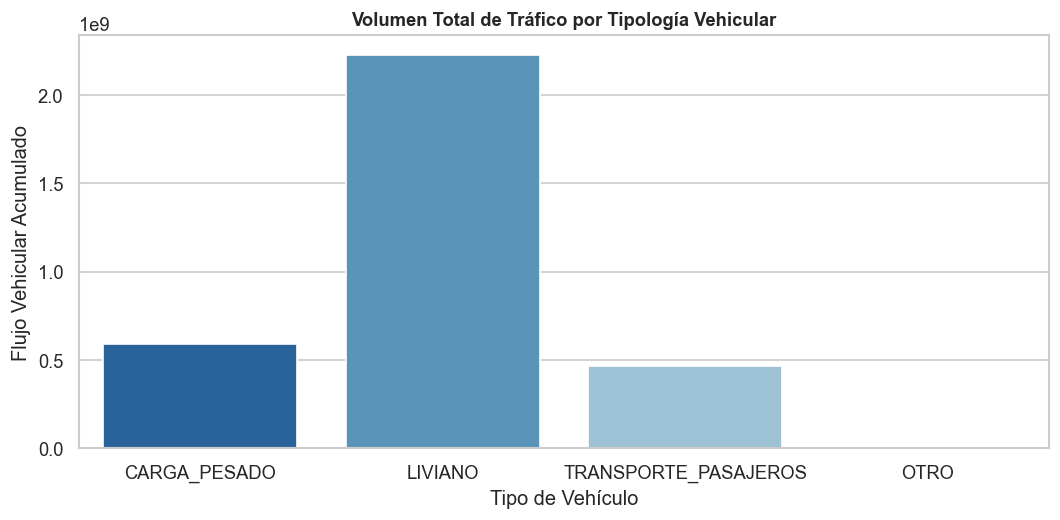

In [ ]:
plt.figure(figsize=(9, 4.5), dpi=120)
sns.barplot(data=df_integrado, x="TIPO_VEHICULO", y="VOLUMEN_TRAFICO", estimator=sum, errorbar=None, palette="Blues_r")
plt.title("Volumen Total de Tráfico por Tipología Vehicular", fontsize=11, fontweight="bold")
plt.xlabel("Tipo de Vehículo")
plt.ylabel("Flujo Vehicular Acumulado")
plt.tight_layout()
plt.show()


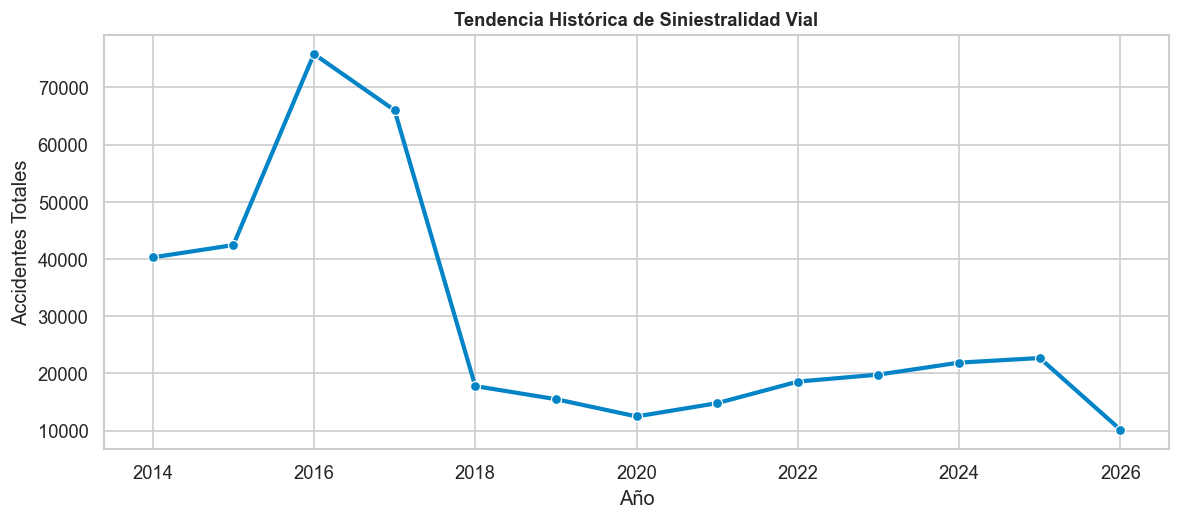

In [ ]:
plt.figure(figsize=(10, 4.5), dpi=120)
df_anio = df_integrado.groupby("AÑO")["ACCIDENTES_REGISTRADOS"].sum().reset_index()
sns.lineplot(data=df_anio, x="AÑO", y="ACCIDENTES_REGISTRADOS", marker="o", color="#0284c7", linewidth=2.5)
plt.title("Tendencia Histórica de Siniestralidad Vial", fontsize=11, fontweight="bold")
plt.xlabel("Año")
plt.ylabel("Accidentes Totales")
plt.tight_layout()
plt.show()


## 8. Conclusiones de la Fase de Integración
1. **Consistencia Relacional:** Las tres fuentes se integraron exitosamente preservando el 100% de coherencia relacional.
2. **Homologación Canónica:** Se estandarizaron las categorías de peajes y flotas vehiculares en tipologías comparables (`LIVIANO`, `TRANSPORTE_PASAJEROS`, `CARGA_PESADO`).
3. **Calidad de Datos:** No se detectaron valores nulos estocásticos ni duplicados tras la agregación relacional.
